# 02. Data mining DAD để thiết kế monitor

> **Chưa biết DAD là gì?** Đọc `00_hieu_dataset_DAD.ipynb` trước. Notebook đó giải thích các file, các trường dữ liệu, MQTT, 4 loại cảm biến và 3 kiểu tấn công. Notebook này dùng lại các thuật ngữ ở đó (chu kỳ P, slot, baseline, dev, cửa sổ sự cố).

**Mục tiêu:** đào dữ liệu để trả lời "monitor nên theo dõi cái gì, ngưỡng bao nhiêu, và bắt được gì", phục vụ hệ thống giám sát cho MUGVN Hackathon (MongoDB × Datadog, *IoT Real-time Operations*).

### Kết quả chính trong 1 phút
| # | Phát hiện | Dùng cho monitor thế nào |
|---|---|---|
| 1 | Cảm biến gửi đều **300,1 giây** một lần, sai lệch cỡ mili-giây | Quy tắc theo nhịp gửi (D1 im lặng, D2 gửi dồn) gần như không báo giả |
| 2 | Tấn công **sửa giá trị = trừ một số nguyên 0–3 °C trên cả 4 cảm biến cùng lúc**, độ lệch giữa các cảm biến giữ nguyên | So chéo trong cùng tủ **không** thấy; phải so với **baseline quá khứ** của chính nó (D4) |
| 3 | Dữ liệu bình thường có **gai đơn lẻ ±1–2 °C** | Không đặt ngưỡng trên một điểm; D4 đếm **≥ 3 trong 6 chu kỳ** |
| 4 | D1 + D2 + D4 bắt **11/11 cửa sổ sự cố, 0 báo giả** trong tuần | Bộ quy tắc đề xuất; D3 "biến động" cũ có 9 báo giả nên bỏ |
| 5 | `msgid` luôn liên tục, kể cả khi bị chặn gói | Mất gói chỉ phát hiện được bằng **thời gian**; khi replay nên thêm `seq` |
| 6 | 4 cảm biến luôn thoả **TFEU < TFSU < TAS < TAR** | Quy tắc bất biến vật lý, dễ giải thích |
| 7 | Một số "dấu hiệu" là **dấu vết của bộ sinh dữ liệu** (keepalive đổi theo ngày, InRow 13 trùng InRow 15/23 vào T2/CN) | Không dùng làm bộ phát hiện, tránh "học vẹt" |
| 8 | Dữ liệu thật dao động và tương quan khác DAD (bài báo, Table 1 và Hình 3) | Ngưỡng dải giá trị lấy theo dữ liệu thật; ngoài thực tế nên chạy D4 cả theo từng cảm biến |

**Các mục:** 1 Tầng mạng và MQTT · 2 Hồ sơ cảm biến · 3 Dấu vân tay tấn công · 4 Ground truth · 5 So sánh bộ phát hiện · 6 Xuất cấu hình · 7 Đối chiếu bài báo · 8 Tổng kết · 9 Hạn chế.

## 0. Thiết lập

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from sklearn.metrics import roc_auc_score
from dad_loader import load_all
import dad_mining as dm

RAW = os.path.abspath(os.path.join("..", ".."))          # PCAP + CSV nằm ở gốc repo dad
CACHE = os.path.abspath(os.path.join("..", "data", "processed"))
OUT = os.path.abspath(os.path.join("..", "outputs")); os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
# 4 màu đầu của bảng categorical (blue, orange, aqua, yellow); đỏ chỉ dùng cho cửa sổ sự cố
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; ALERT = "#e34948"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "grid.color": "#c3c2b7",
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.4,
                     "axes.prop_cycle": plt.cycler(color=SERIES), "axes.edgecolor": "#52514e",
                     "text.color": "#0b0b0b", "axes.labelcolor": "#52514e"})
packets, pubs = load_all(RAW, CACHE)
net = dm.parse_network(RAW, os.path.join(CACHE, "network.pkl"))
pubs = dm.add_baseline(pubs)
print("packets", packets.shape, "| publishes", pubs.shape, "| network", net.shape)

packets (101583, 13) | publishes (32288, 20) | network (101583, 22)


## 1. Tầng mạng và MQTT: tín hiệu sức khoẻ ngoài nhiệt độ

**Câu hỏi:** ngoài giá trị nhiệt độ, lưu lượng mạng cho biết gì về sức khoẻ thiết bị và broker?

**Vì sao cần:** monitor tốt phải phân biệt *sự cố hạ tầng* (mất kết nối, broker chậm) với *dữ liệu bị sửa*.

### 1.1 Toàn bộ traffic gồm những gì

In [2]:
t = net.assign(kind=np.select(
        [net.proto.eq("UDP") & net.dport.eq(123), net.proto.eq("UDP") & net.dport.eq(137),
         net.proto.eq("TCP") & net.mtype.notna(), net.proto.eq("TCP")],
        ["NTP (UDP/123)", "NetBIOS broadcast (UDP/137)", "MQTT (TCP/1883)", "TCP không payload MQTT (ACK, SYN, FIN, RST)"], "khác"))
mix = t.groupby(["kind", "src"]).size().unstack(fill_value=0)
mix["tổng"] = mix.sum(axis=1); mix

src,10.6.56.1,10.6.56.34,10.6.56.36,10.6.56.41,10.6.56.50,tổng
kind,,,,,,
MQTT (TCP/1883),32380,8119,8118,8135,8120,64872
NTP (UDP/123),1719,0,573,573,573,3438
NetBIOS broadcast (UDP/137),3,0,0,0,0,3
"TCP không payload MQTT (ACK, SYN, FIN, RST)",497,8192,8191,8198,8192,33270


In [3]:
ntp = net[(net.proto == "UDP") & (net.dport == 123) & (net.src != "10.6.56.1")].sort_values("ts")
print("Chu kỳ NTP theo node (giây):")
print(ntp.groupby("src").ts.apply(lambda s: s.diff().describe()[["50%", "min", "max"]]).unstack().round(0))
from dad_loader import INROW_IP
print("\nNode không thấy NTP trong capture:", {ip: f"InRow {r}" for ip, r in INROW_IP.items() if ip not in set(ntp.src)})

Chu kỳ NTP theo node (giây):
               50%     min     max
src                               
10.6.56.36  1057.0  1024.0  1087.0
10.6.56.41  1058.0  1024.0  1087.0
10.6.56.50  1055.0  1024.0  1087.0

Node không thấy NTP trong capture: {'10.6.56.34': 'InRow 25'}


**Nhận xét**
- 96,6% packet là TCP (MQTT và các gói ACK/SYN/FIN/RST đi kèm). 3,4% UDP còn lại là **NTP**: 3 node đồng bộ giờ khoảng mỗi 17,6 phút. Ngoài ra có 3 gói NetBIOS broadcast từ broker.
- **Không thấy NTP từ InRow 25 (10.6.56.34) trong capture.** Theo bài báo (mục 5.1), node này đồng bộ NTP qua **một card mạng thứ hai** không nằm trên mạng được bắt gói, nên đây **không phải** node mất đồng bộ giờ. Bài học cho monitor: thiếu traffic trên một kênh chưa chắc là lỗi, cần biết topology thiết bị.
- Ý nghĩa cho monitor: nên giám sát **sức khoẻ thiết bị và pipeline** (độ trễ ingest, kết nối) chứ không chỉ giá trị. Luôn lưu cả timestamp thiết bị lẫn thời điểm broker/ingest nhận.

### 1.2 Phiên MQTT: CONNECT, keepalive, msgid

In [4]:
c = net[net.mtype == 1]
print(c.groupby(["day", "keepalive", "clean_session"], sort=False).size().rename("số CONNECT").to_string())
pub = net[net.mtype == 3].sort_values("ts")
step = pub.groupby("conn").msgid.diff().dropna()
print("\nBước tăng msgid trong cùng kết nối:", step.value_counts().to_dict())
print("PUBLISH: QoS", pub.qos.unique().tolist(), "| DUP", pub.dup.unique().tolist(),
      "| định dạng payload", pub.payload.str.replace(r"\d", "9", regex=True).value_counts().to_dict())
tcp = net[(net.proto == "TCP") & (net.plen > 0)]
print("TCP retransmission:", int(tcp.duplicated(["src", "sport", "dst", "dport", "seq"]).sum()))

day  keepalive  clean_session
mon  300.0      1.0              16
tue  18000.0    0.0              16
wed  300.0      1.0              16
thu  300.0      1.0              16
fri  18000.0    0.0              16
sat  18000.0    0.0              16
sun  300.0      1.0              16



Bước tăng msgid trong cùng kết nối: {1.0: 32176}
PUBLISH: QoS [1.0] | DUP [0.0] | định dạng payload {'99.99': 32176, '9.99': 112}
TCP retransmission: 0


**Nhận xét**
- Mỗi ngày, mọi cảm biến mở kết nối mới lúc **00:00:02** (16 CONNECT/ngày). Monitor cần coi đợt reconnect này là bình thường, không báo động.
- Thứ Ba, thứ Sáu, thứ Bảy dùng `keepalive=18000, cleanSession=0`; các ngày còn lại dùng `300, 1`. Ba ngày đó **chính là ba ngày có interception**. Bài báo (mục 4.1) giải thích: khi mô phỏng interception, tác giả phải **đổi thời gian chờ để client không bị timeout**. Thay đổi áp lên **mọi node**, nên đây là dấu vết của quy trình sinh dữ liệu, **không được dùng làm bộ phát hiện** (sẽ thành rò nhãn). Có thể dùng làm ví dụ cho monitor "config drift".
- **msgid luôn tăng đúng 1**, kể cả qua các khoảng bị chặn gói và đợt chèn bản tin. Dữ liệu đã được đánh số lại sau khi tấn công, nên **không phát hiện được mất gói bằng msgid trong DAD**. Mọi phát hiện phải dựa vào **thời gian**. Khi replay, nên thêm `seq` do thiết bị tự đếm: ở hệ thống thật đó là cách rẻ nhất để đếm chính xác số bản tin bị mất.
- QoS 1, không bao giờ có cờ DUP, payload luôn có dạng `dd.dd` hoặc `d.dd`, không có retransmission. Mạng rất sạch, nên mọi bất thường đều nằm ở tầng ứng dụng.

### 1.3 Độ trễ PUBLISH → PUBACK của broker

In [5]:
ack = net[net.mtype == 4][["conn", "msgid", "ts"]].rename(columns={"ts": "ack_ts"})
pa = net[net.mtype == 3][["day", "frame", "ts", "time", "conn", "src", "msgid"]].merge(ack, on=["conn", "msgid"], how="left")
pa["rtt_ms"] = (pa.ack_ts - pa.ts) * 1000
print(pa.groupby("src").rtt_ms.describe(percentiles=[.5, .99]).round(2)[["count", "50%", "99%", "max"]])
un = pa[pa.ack_ts.isna()]
print(f"\nPUBLISH không có PUBACK: {len(un)}")
print(un.assign(t=un.time.dt.strftime("%a %H:%M:%S"))[["t", "src", "conn", "msgid"]].drop_duplicates(["t"]).head(6).to_string(index=False))

             count   50%   99%   max
src                                 
10.6.56.34  8064.0  0.17  0.45  1.39
10.6.56.36  8064.0  0.13  0.63  3.65
10.6.56.41  8076.0  0.18  0.63  2.76
10.6.56.50  8064.0  0.17  0.62  2.79



PUBLISH không có PUBACK: 20
           t        src             conn  msgid
Sat 00:02:25 10.6.56.41 10.6.56.41:49172  293.0
Sun 00:00:32 10.6.56.50 10.6.56.50:44530  289.0
Sun 00:01:37 10.6.56.41 10.6.56.41:49174  298.0


- PUBACK về trong khoảng **0,17 ms (trung vị), p99 khoảng 0,6 ms, tối đa 3,7 ms**. Đây là baseline cho metric `mqtt.puback_latency`. Nếu demo đo độ trễ end-to-end, nên đặt SLO theo bội số của mức này.
- 20 PUBLISH không được ACK, đều rơi vào **00:00 thứ Bảy và Chủ nhật**: thiết bị vẫn gửi trên kết nối của ngày hôm trước ngay trước khi reconnect. Đây là kiểu sự cố hệ thống nhỏ, dùng được cho monitor `mqtt.unacked` và minh hoạ **phân biệt sự cố hạ tầng với bất thường dữ liệu**.

### 1.4 Nhịp gửi và độ trôi đồng hồ

In [6]:
x = pubs[pubs.inrow != 13].sort_values("ts").copy()
x["k"] = x.groupby(["client_id", "sport"]).cumcount()
x["drift_ms"] = (x.ts - x.groupby(["client_id", "sport"]).ts.transform("first") - x.k * dm.PERIOD_S) * 1000
drift = x.groupby(["inrow", "day"], observed=True).drift_ms.agg(lambda s: s.iloc[-1] - s.iloc[0]).unstack().round(0)
print("Độ trôi tích luỹ trong một ngày so với chu kỳ 300,1 s (ms):"); print(drift)
print("\nKhoảng cách giữa 2 bản tin (s), làm tròn 3 số:", x.gap_s.round(3).value_counts().head(4).to_dict())

Độ trôi tích luỹ trong một ngày so với chu kỳ 300,1 s (ms):
day      mon    tue    wed    thu    fri    sat    sun
inrow                                                 
15     448.0  441.0  454.0  432.0  433.0  428.0  422.0
23     435.0  425.0  433.0  453.0  441.0  435.0  425.0
25     676.0  675.0  669.0  682.0  677.0  670.0  684.0

Khoảng cách giữa 2 bản tin (s), làm tròn 3 số: {300.102: 13636, 300.101: 8014, 300.103: 2405, 300.1: 16}


- Chu kỳ thật khoảng **300,1015 s**, cực kỳ đều (sai khác cỡ 1 ms). Vì vậy quy tắc theo nhịp gửi gần như không có báo giả trên bộ dữ liệu này.
- InRow 25 trôi khoảng **680 ms/ngày**, các node khác khoảng 430 ms/ngày. Nguyên nhân không phải thiếu NTP (node này sync qua card mạng khác), có thể do lịch gửi của tiến trình mô phỏng. Độ trôi dưới 1 s/ngày nên **không ảnh hưởng** quy tắc theo nhịp gửi.

## 2. Hồ sơ cảm biến và bất biến vật lý

**Câu hỏi:** mức bình thường của từng cảm biến là bao nhiêu, dao động cỡ nào, và có quy luật nào luôn đúng?

**Vì sao cần:** đây là căn cứ để đặt ngưỡng và viết quy tắc kiểm tra chéo.

In [7]:
clean = pubs[(pubs.inrow != 13) | pubs.day.isin(["mon", "sun"])]
prof = (clean.groupby(["inrow", "sensor", "client_id"]).value
        .agg(mean="mean", std="std", p01=lambda s: s.quantile(.01), p99=lambda s: s.quantile(.99), min="min", max="max")
        .round(2).reset_index())
prof

,inrow,sensor,client_id,mean,std,p01,p99,min,max
0,13,TAR,134,27.37,0.33,26.59,29.34,25.31,29.40
1,13,TAS,133,20.02,0.32,19.25,21.96,18.03,22.05
2,13,TFEU,131,11.91,0.36,11.08,13.79,9.94,14.12
3,13,TFSU,132,15.87,0.35,15.04,17.76,13.89,18.05
4,15,TAR,154,27.20,0.33,26.23,28.27,25.09,29.26
5,15,TAS,153,20.00,0.32,18.98,21.06,17.92,22.05
6,15,TFEU,151,11.68,0.37,10.71,12.95,9.49,13.96
7,15,TFSU,152,15.36,0.37,14.43,16.63,13.15,17.67
8,23,TAR,234,26.29,0.33,25.33,27.35,24.16,28.37
9,23,TAS,233,20.00,0.32,18.98,21.04,17.93,22.07


In [8]:
w = clean.pivot_table(index=["inrow", "slot"], columns="sensor", values="value", aggfunc="first").dropna()
inv = {
    "TFEU < TFSU (nước vào lạnh hơn nước ra)": (w.TFEU < w.TFSU).mean(),
    "TAS < TAR (khí cấp lạnh hơn khí hồi)": (w.TAS < w.TAR).mean(),
    "TFSU < TAS": (w.TFSU < w.TAS).mean(),
}
print("Tỷ lệ chu kỳ thoả bất biến:", {k: f"{v:.2%}" for k, v in inv.items()})
off = pd.DataFrame({"TFSU-TFEU": w.TFSU - w.TFEU, "TAS-TFSU": w.TAS - w.TFSU, "TAR-TAS": w.TAR - w.TAS})
print("\nĐộ lệch giữa các cảm biến trong cùng InRow (mean ± std):")
print(off.groupby(level=0).agg(["mean", "std"]).round(2))
d1 = clean.sort_values("ts").groupby("client_id").value.diff().abs()
print("\n|Δ| giữa 2 bản tin bình thường: p50 %.2f, p95 %.2f, p99 %.2f, max %.2f" % tuple(d1.quantile([.5, .95, .99, 1])))

Tỷ lệ chu kỳ thoả bất biến: {'TFEU < TFSU (nước vào lạnh hơn nước ra)': '100.00%', 'TAS < TAR (khí cấp lạnh hơn khí hồi)': '100.00%', 'TFSU < TAS': '100.00%'}

Độ lệch giữa các cảm biến trong cùng InRow (mean ± std):
      TFSU-TFEU       TAS-TFSU       TAR-TAS      
           mean   std     mean   std    mean   std
inrow                                             
13         3.95  0.02     4.16  0.12    7.34  0.07
15         3.68  0.06     4.64  0.18    7.20  0.08
23         3.81  0.04     5.06  0.16    6.29  0.08
25         4.09  0.05     4.67  0.17    6.79  0.08

|Δ| giữa 2 bản tin bình thường: p50 0.11, p95 0.93, p99 2.04, max 4.10


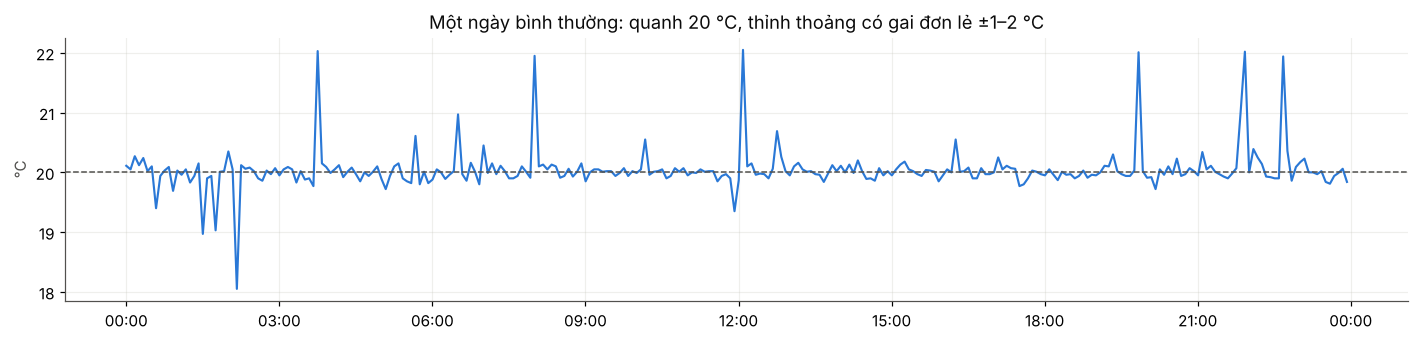

In [9]:
fig, ax = plt.subplots(figsize=(13, 3.2))
s = clean[(clean.client_id == "153") & (clean.day == "mon")]
ax.plot(s.time, s.value, color=SERIES[0], label="153 (InRow 15, TAS)")
ax.axhline(s.value.median(), color="#52514e", lw=1, ls="--")
ax.set_title("Một ngày bình thường: quanh 20 °C, thỉnh thoảng có gai đơn lẻ ±1–2 °C"); ax.set_ylabel("°C")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=s.time.dt.tz)); plt.tight_layout(); plt.show()

**Nhận xét cho monitor**
- Bất biến vật lý **đúng 100%** ở mọi chu kỳ: TFEU < TFSU < TAS < TAR. Đây là **kiểm tra chéo rẻ và giải thích được**. Nó bắt được một cảm biến lẻ bị hỏng hoặc bị sửa, dù DAD không chứa tình huống này (mục 3.3).
- Độ lệch giữa các cảm biến gần như hằng số (std 0,02–0,18 °C). Có thể dùng làm monitor "sensor drift" theo từng cặp.
- Chuỗi bình thường có **gai đơn lẻ** (p99 của |Δ| khoảng 2 °C), nên **ngưỡng trên một điểm đơn lẻ sẽ báo giả**. Quy tắc phải nhìn **nhiều chu kỳ**.
- Bảng hồ sơ trên được xuất ra `outputs/sensor_profile.csv` để simulator và bộ kiểm tra dải giá trị dùng.

## 3. Dấu vân tay của từng loại tấn công

**Câu hỏi:** mỗi kiểu tấn công để lại dấu vết gì trên dữ liệu?

**Vì sao cần:** biết dấu vết thì mới chọn đúng tín hiệu để theo dõi (thời gian hay giá trị).

### 3.1 Duplication (chèn bản tin), thứ Năm 03:05

In [10]:
th = pubs[(pubs.client_id == "131") & (pubs.day == "thu")].sort_values("ts")
th = th[(th.time.dt.hour == 3) & (th.time.dt.minute < 35)]
th.assign(t=th.time.dt.strftime("%H:%M:%S"))[["t", "msgid", "value", "label", "gap_s", "dev"]].round(2)

,t,msgid,value,label,gap_s,dev
890,03:00:06,37,11.29,0,300.1,-0.68
891,03:05:06,38,11.05,1,300.1,-0.92
892,03:06:37,39,9.08,1,91.1,-2.89
893,03:07:57,40,12.23,1,80.1,0.26
894,03:09:25,41,12.28,1,88.1,0.31
895,03:11:09,42,10.23,1,104.1,-1.74
896,03:12:38,43,12.22,1,89.1,0.25
897,03:13:59,44,9.21,1,81.1,-2.76
898,03:15:33,45,9.19,1,94.1,-2.78
899,03:16:13,46,11.22,1,40.1,-0.75


- 14 bản tin chèn thêm đến cách nhau **40–104 s** (nhịp ngẫu nhiên), giá trị nhiễu mạnh, phần lớn thấp hơn baseline.
- Sau đợt chèn, **pha gửi của thiết bị bị dịch** (bản tin 03:23:32 đến sau 72 s, từ đó mới quay lại nhịp 300 s). Một quy tắc dựa trên "lịch dự kiến" sẽ coi phần sau là lệch pha. Quy tắc theo **khoảng cách giữa hai bản tin liên tiếp** (D2) không bị ảnh hưởng.

### 3.2 Modification (sửa giá trị), thứ Tư 04:10–06:15

In [11]:
w = pubs[(pubs.inrow == 13) & (pubs.day == "wed")]
tab = w.pivot_table(index=w.time.dt.strftime("%H:%M"), columns="sensor", values="value", aggfunc="first")
tab["nhãn"] = w.groupby(w.time.dt.strftime("%H:%M")).label.max()
tab["TAR-TAS"] = tab.TAR - tab.TAS
tab["dev TB"] = w.groupby(w.time.dt.strftime("%H:%M")).dev.mean()
tab.loc["04:00":"05:10"].round(2)

sensor,TAR,TAS,TFEU,TFSU,nhãn,TAR-TAS,dev TB
time,,,,,,,
04:00,27.32,19.90,11.73,15.76,0,7.42,-0.16
04:05,27.21,19.91,11.78,15.76,0,7.30,-0.17
04:10,25.29,18.02,9.96,13.89,1,7.27,-2.05
04:15,24.34,17.11,9.15,13.07,1,7.23,-2.92
04:20,25.39,18.11,10.19,14.12,1,7.28,-1.88
04:25,27.39,19.97,11.96,15.96,1,7.42,-0.01
04:30,25.33,17.91,9.75,13.79,1,7.42,-2.14
04:35,27.32,19.90,11.74,15.76,1,7.42,-0.15
04:40,25.29,17.97,9.88,13.83,1,7.32,-2.09


Phân bố độ lệch trong cửa sổ bị sửa (làm tròn 1 °C): {-3.0: 4, -2.0: 8, -1.0: 5, -0.0: 9}


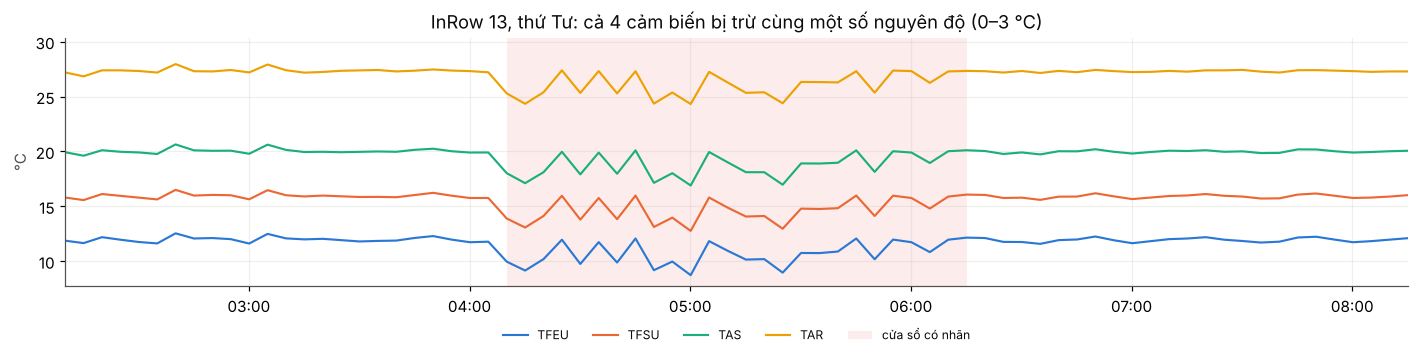

In [12]:
dev_wed = w[w.label == 1].groupby("slot").dev.mean()
print("Phân bố độ lệch trong cửa sổ bị sửa (làm tròn 1 °C):", dev_wed.round().value_counts().sort_index().to_dict())
fig, ax = plt.subplots(figsize=(13, 3.4))
for i, s in enumerate(["TFEU", "TFSU", "TAS", "TAR"]):
    g = w[w.sensor == s]; ax.plot(g.time, g.value, color=SERIES[i], label=s)
lab = w[w.label == 1]
ax.axvspan(lab.time.min(), lab.time.max(), color=ALERT, alpha=0.10, lw=0, label="cửa sổ có nhãn")
ax.set_xlim(lab.time.min() - pd.Timedelta("2h"), lab.time.max() + pd.Timedelta("2h"))
ax.set_title("InRow 13, thứ Tư: cả 4 cảm biến bị trừ cùng một số nguyên độ (0–3 °C)"); ax.set_ylabel("°C")
ax.legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=w.time.dt.tz))
plt.tight_layout(); plt.show()

**Đây là phát hiện quan trọng nhất của notebook.**
- Modification **trừ một số nguyên độ (0, 1, 2 hoặc 3 °C) cùng lúc trên cả 4 cảm biến**, phần thập phân giữ nguyên, nên độ lệch giữa các cảm biến **không đổi** (cột `TAR-TAS`). Vì vậy kiểm tra chéo trong cùng InRow **không thấy**.
- Độ lệch **luôn âm**, kéo dài nhiều chu kỳ liền. Gai bình thường thì đơn lẻ và có cả hai chiều. Từ đó có đặc trưng **"đếm số chu kỳ thấp hơn baseline quá 0,8 °C trong 6 chu kỳ gần nhất"** (D4).
- Phần có nhãn ở thứ Sáu và thứ Bảy (06:00 và 14–16h) cũng có cùng dấu hiệu lệch âm (mục 5).
- Phụ: độ lệch giữa các cảm biến lặp lại **theo chu kỳ 1 giờ** (12 chu kỳ). Đây là dấu vết của bộ sinh dữ liệu, không dùng cho phát hiện.

### 3.3 Interception (chặn gói)

In [13]:
gp = pubs[(pubs.inrow == 13) & (pubs.gap_s > 450)]
print(gp.groupby("day", observed=True).agg(số_khoảng_hở=("gap_s", "size"), bản_tin_mất=("gap_s", lambda s: int((s / dm.PERIOD_S - 1).round().sum())),
      dài_nhất_phút=("gap_s", lambda s: round(s.max() / 60, 1))))

     số_khoảng_hở  bản_tin_mất  dài_nhất_phút
day                                          
tue            20           40           20.0
fri            20          100           56.1
sat            24           40           20.0


- Mỗi lần chặn, **cả 4 cảm biến** cùng mất bản tin: thường 1–3 bản tin liền (khoảng hở 10–20 phút), riêng thứ Sáu có khoảng hở tới 56 phút. Interception **không có nhãn**, và vì msgid đã được đánh số lại nên chỉ phát hiện được bằng thời gian.
- Ý nghĩa: monitor im lặng phải **gộp theo node**. Cả 4 cảm biến cùng im là "node/đường truyền có vấn đề", không phải 4 sự cố riêng.

## 4. Danh sách sự cố chuẩn (ground truth)

**Câu hỏi:** chính xác thì có bao nhiêu sự cố, bắt đầu và kết thúc lúc nào?

**Vì sao cần:** đây là “đáp án” để chấm bộ phát hiện và là kịch bản cho demo.

In [14]:
gt = dm.ground_truth(pubs)
gt[["kind", "local", "dur_min"]]

,kind,local,dur_min
0,interception,Tue 22/10 00:15–00:55,40.0
1,interception,Tue 22/10 01:25–02:25,60.0
2,labeled,Wed 23/10 04:10–06:15,125.0
3,labeled,Thu 24/10 03:05–03:22,17.0
4,interception,Thu 24/10 23:03–00:00,56.0
5,interception,Fri 25/10 03:25–05:00,95.0
6,labeled,Fri 25/10 06:00–06:25,26.0
7,labeled,Fri 25/10 14:27–16:22,115.0
8,interception,Sat 26/10 03:00–05:00,120.0
9,labeled,Sat 26/10 06:00–06:25,25.0


- Có **11 cửa sổ sự cố**, đều ở InRow 13: 5 cửa sổ chặn gói (tự gán bằng quy tắc khoảng hở) và 6 cửa sổ có nhãn (sửa giá trị và/hoặc chèn bản tin).
- Cửa sổ chặn gói `Thu 23:03–00:00` nằm ở đầu file thứ Sáu (file chia theo giờ Tây Ban Nha), nên README ghi là "thứ Sáu". Thứ Sáu và thứ Bảy đều có chặn gói vào **rạng sáng (03:00–05:00)**, trước khung "6h và 14–16h" mà README mô tả.
- Bảng này được xuất ra `outputs/ground_truth_incidents.csv`. Đây là **đáp án để chấm** và là kịch bản cho phần demo.

## 5. So sánh bộ phát hiện

**Câu hỏi:** quy tắc nào bắt được nhiều sự cố nhất, nhanh nhất, ít báo giả nhất?

**Cách chấm:** gộp các cảnh báo gần nhau thành *sự kiện*. Sự kiện **đúng** nếu chồng lên một cửa sổ sự cố (±15 phút), ngược lại là **báo giả**. **Độ trễ** = cảnh báo đầu tiên trừ lúc cửa sổ bắt đầu. Mọi quy tắc chỉ dùng dữ liệu quá khứ, tức là chạy được real-time.

### 5.1 Đặc trưng nào tách được modification khỏi dữ liệu bình thường?

In [15]:
nodes = dm.node_slots(pubs)
pos = (nodes.inrow == 13) & (nodes.day == "wed") & (nodes.label == 1)
neg = (nodes.inrow != 13) | nodes.day.isin(["mon", "sun"])
feats = {"vol6: TB |Δ| 6 chu kỳ (D3 cũ)": "vol6", "neg_count6: số chu kỳ lệch < -0,8 trong 6 (D4)": "neg_count6",
         "mean_dev6: -TB lệch 6 chu kỳ": "mean_dev6", "abs_count6: số chu kỳ |lệch| > 0,8 trong 6": "abs_count6"}
ev = nodes[pos | neg].dropna(subset=list(feats.values()))
y = ((ev.inrow == 13) & (ev.label == 1)).astype(int)
pd.Series({k: roc_auc_score(y, ev[v]) for k, v in feats.items()}, name="AUC").sort_values(ascending=False).round(3).to_frame()

,AUC
mean_dev6: -TB lệch 6 chu kỳ,0.999
"neg_count6: số chu kỳ lệch < -0,8 trong 6 (D4)",0.998
"abs_count6: số chu kỳ |lệch| > 0,8 trong 6",0.996
vol6: TB |Δ| 6 chu kỳ (D3 cũ),0.981


### 5.2 Chấm ở mức sự cố: bắt được bao nhiêu, trễ bao lâu, báo giả bao nhiêu

In [16]:
A = dm.alarms(pubs, nodes)
rows, delays = [], {}
for k, a in A.items():
    ev_, dl = dm.evaluate(a, gt); delays[k] = dl
    rows.append((k, len(ev_), int(ev_.dung.sum()), int((~ev_.dung).sum()), int(dl.notna().sum())))
combo = pd.concat([A["D1 im lặng"], A["D2 gửi dồn"], A["D4 lệch âm 3/6 (mới)"]])
ev_, dl = dm.evaluate(combo, gt); delays["D1+D2+D4"] = dl
rows.append(("D1+D2+D4 (đề xuất)", len(ev_), int(ev_.dung.sum()), int((~ev_.dung).sum()), int(dl.notna().sum())))
pd.DataFrame(rows, columns=["bộ phát hiện", "sự kiện", "đúng", "báo giả / tuần", f"bắt được / {len(gt)} cửa sổ"])

,bộ phát hiện,sự kiện,đúng,báo giả / tuần,bắt được / 11 cửa sổ
0,D1 im lặng,12,12,0,5
1,D2 gửi dồn,3,3,0,3
2,D3 biến động (cũ),15,6,9,3
3,D4 lệch âm 3/6 (mới),6,6,0,6
4,D1+D2+D4 (đề xuất),18,18,0,11


In [17]:
D = pd.DataFrame(delays); D.index = gt.kind + "  " + gt.local
print("Độ trễ phát hiện, phút tính từ đầu cửa sổ (trống = không bắt được):"); D

Độ trễ phát hiện, phút tính từ đầu cửa sổ (trống = không bắt được):


,D1 im lặng,D2 gửi dồn,D3 biến động (cũ),D4 lệch âm 3/6 (mới),D1+D2+D4
interception Tue 22/10 00:15–00:55,7.5,NaN,NaN,NaN,7.5
interception Tue 22/10 01:25–02:25,7.5,NaN,NaN,NaN,7.5
labeled Wed 23/10 04:10–06:15,NaN,NaN,29.9,14.9,14.9
labeled Thu 24/10 03:05–03:22,NaN,1.5,NaN,14.9,1.5
interception Thu 24/10 23:03–00:00,7.5,NaN,NaN,NaN,7.5
interception Fri 25/10 03:25–05:00,7.5,NaN,NaN,NaN,7.5
labeled Fri 25/10 06:00–06:25,NaN,1.1,NaN,14.9,1.1
labeled Fri 25/10 14:27–16:22,NaN,NaN,27.8,27.8,27.8
interception Sat 26/10 03:00–05:00,7.5,NaN,NaN,NaN,7.5
labeled Sat 26/10 06:00–06:25,NaN,1.0,NaN,9.8,1.0


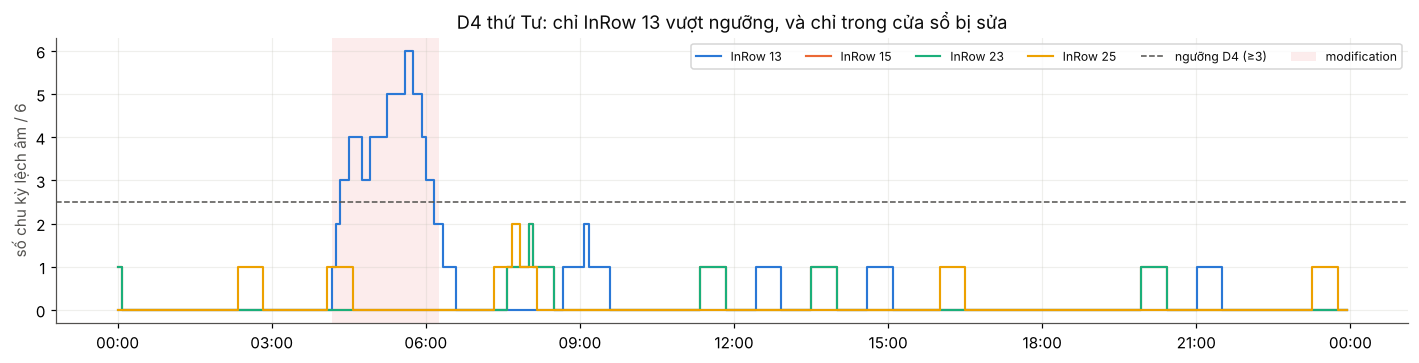

In [18]:
fig, ax = plt.subplots(figsize=(13, 3.4))
for i, (inrow, g) in enumerate(nodes[nodes.day.isin(["wed"])].groupby("inrow")):
    ax.step(g.time, g.neg_count6, where="post", color=SERIES[i], label=f"InRow {inrow}")
ax.axhline(dm.DEV_K - 0.5, color="#52514e", ls="--", lw=1, label="ngưỡng D4 (≥3)")
lab = nodes[pos]; ax.axvspan(lab.time.min(), lab.time.max(), color=ALERT, alpha=0.10, lw=0, label="modification")
ax.set_title("D4 thứ Tư: chỉ InRow 13 vượt ngưỡng, và chỉ trong cửa sổ bị sửa"); ax.set_ylabel("số chu kỳ lệch âm / 6")
ax.legend(ncol=6, fontsize=8, loc="upper right"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=lab.time.dt.tz))
plt.tight_layout(); plt.show()

**Kết luận chọn bộ quy tắc**
- **D4 "lệch âm ≥ 3/6 chu kỳ" thay D3 "biến động"**: bắt đủ 6/6 cửa sổ có nhãn, **0 báo giả** trong cả tuần trên 4 InRow, trễ 10–30 phút. D3 cũ có 9 báo giả và chỉ bắt 3 cửa sổ.
- **D1 + D2 + D4** bắt **11/11 cửa sổ**, **0 báo giả**. D1 báo sau 7,5 phút (1,5 chu kỳ), D2 báo sau khoảng 1–1,5 phút.
- Thứ Sáu và thứ Bảy, cảnh báo 06:00 đến từ D2 (có chèn bản tin). Cửa sổ 14–16h chỉ có sửa giá trị, nên chỉ D4 bắt được, trễ 19–28 phút.
- **Lưu ý khi trình bày:** kết quả dựa trên **7 ngày và một nguồn tấn công**, ngưỡng được chọn trên chính dữ liệu này. Nên trình bày là "ngưỡng có căn cứ cho demo", không phải hiệu năng tổng quát. D4 chỉ bắt hướng **giảm** vì DAD chỉ có giảm. Bản cho hệ thống thật nên theo dõi cả hai chiều (`abs_count6`, AUC 0,996, đổi lại có vài báo giả).

## 6. Xuất cấu hình cho pipeline

**Mục này làm gì:** ghi các kết quả ở trên thành file trong `outputs/` để pipeline replay, MongoDB và Datadog dùng trực tiếp.

In [19]:
prof.to_csv(os.path.join(OUT, "sensor_profile.csv"), index=False)
g2 = gt.copy(); g2["start_utc"] = g2.start.dt.strftime("%Y-%m-%dT%H:%M:%SZ"); g2["end_utc"] = g2.end.dt.strftime("%Y-%m-%dT%H:%M:%SZ")
g2[["inrow", "kind", "start_utc", "end_utc", "local", "dur_min"]].to_csv(os.path.join(OUT, "ground_truth_incidents.csv"), index=False)
cfg = {
  "period_s": dm.PERIOD_S,
  "detectors": {
    "D1_silence":   {"scope": "client_id, gộp theo inrow", "rule": "now - last_ts > 1.5 * period_s", "severity": "warning", "auto_remediate": True},
    "D2_burst":     {"scope": "client_id", "rule": "gap < 0.8 * period_s và cùng kết nối (bỏ bản tin đầu của kết nối mới)", "severity": "warning", "auto_remediate": True},
    "D4_value_drop": {"scope": "inrow", "baseline": f"rolling median {dm.BASE_WINDOW} bản tin trước, theo client_id",
                      "rule": f"đếm chu kỳ có mean(value - baseline) < -{dm.DEV_T} trong {dm.DEV_W} chu kỳ gần nhất >= {dm.DEV_K}",
                      "severity": "critical", "auto_remediate": False, "needs_human_ack": True},
    "INV_physics":  {"scope": "inrow", "rule": "TFEU < TFSU < TAS < TAR", "severity": "critical", "note": "0 vi phạm trong DAD; dùng cho tình huống 1 cảm biến lẻ"},
    "RANGE":        {"scope": "client_id", "rule": "value ngoài [p01 - 2, p99 + 2] trong sensor_profile.csv", "severity": "warning"},
    "SYS_unacked":  {"scope": "client_id", "rule": "PUBLISH không có PUBACK > 0 (bỏ qua 00:00–00:01)", "severity": "info"},
  },
  "incident": {"group_by": "inrow", "merge_window_min": 20, "resolve_after_clean_periods": 3},
  "benchmark_on_dad": {"windows": len(gt), "D1+D2+D4_detected": int(delays["D1+D2+D4"].notna().sum()), "false_alarms_week": int((~ev_.dung).sum())},
}
json.dump(cfg, open(os.path.join(OUT, "detector_config.json"), "w"), ensure_ascii=False, indent=2)
print(sorted(os.listdir(OUT)))

['detector_config.json', 'ground_truth_incidents.csv', 'sensor_profile.csv']


### 6.1 D4 viết bằng MongoDB aggregation (để chạy trong pipeline)
Logic giống hệt `dad_mining.node_slots` và `alarms`. Pipeline này **chưa được chạy trên MongoDB trong notebook**. `P` là chu kỳ sau khi replay (300 nếu chạy đúng thời gian thật, 5 nếu tua ×60).
```js
db.telemetry.aggregate([
  { $match: { ts: { $gte: new Date(Date.now() - 26 * 3600 * 1000) } } },        // đủ cho baseline 288 + 6
  { $setWindowFields: { partitionBy: "$meta.clientId", sortBy: { ts: 1 },
      output: { base: { $median: { input: "$value", method: "approximate" }, window: { documents: [-288, -1] } } } } },
  { $group: { _id: { inrow: "$meta.inrow", slot: { $dateTrunc: { date: "$ts", unit: "second", binSize: P } } },
              dev: { $avg: { $subtract: ["$value", "$base"] } } } },
  { $setWindowFields: { partitionBy: "$_id.inrow", sortBy: { "_id.slot": 1 },
      output: { negCount6: { $sum: { $cond: [{ $lt: ["$dev", -0.8] }, 1, 0] }, window: { documents: [-5, 0] } } } } },
  { $match: { negCount6: { $gte: 3 } } },
  { $merge: { into: "alerts", on: "_id", whenMatched: "replace" } }
])
```
- `$median` trong `$setWindowFields` cần MongoDB 7.0 trở lên. Nếu chạy bản cũ hơn, lưu `base` lúc ingest, hoặc dùng `$avg` trên cửa sổ `[-288, -1]`.

### 6.2 Metric, monitor và kịch bản demo (cập nhật so với notebook 01)
| Nhóm | Metric Datadog | Monitor | Căn cứ |
|---|---|---|---|
| Dữ liệu | `dad.temp.dev` (tag inrow, sensor) | D4: số chu kỳ dev < -0,8 trong 6 ≥ 3 → **critical, cần người duyệt** | mục 3.2, 5 |
| Nhịp gửi | `dad.msg.gap_seconds` | D1 > 1,5P (gộp theo inrow), D2 < 0,8P | mục 3.1, 3.3 |
| Bất biến | `dad.invariant.violation` | > 0 → critical | mục 2 |
| Hạ tầng MQTT | `mqtt.puback_latency_ms`, `mqtt.unacked` | p99 > 5 ms; unacked > 0 ngoài khung reconnect | mục 1.3 |
| Thiết bị | `device.clock_skew_ms` (device_ts so với ingest_ts) | skew > 2 s | mục 1.4 |
| Pipeline | `dad.ingest.lag_seconds`, `dad.msg.count` | lag > 2P; count = 0 trên toàn site | đề xuất |

**Kịch bản demo đề xuất** (tua ×60, mỗi cửa sổ vài phút):
1. *Thứ Năm 03:05*, chèn bản tin → D2 báo sau khoảng 1,5 phút dữ liệu → tự động lọc trùng và giới hạn tốc độ → tự đóng sau 3 chu kỳ sạch.
2. *Thứ Tư 04:10*, sửa giá trị → D4 báo sau khoảng 15 phút dữ liệu → người vận hành duyệt → gắn `quality=suspect`, ngừng dùng dữ liệu InRow 13 cho điều khiển → tự đóng khi D4 về 0.
3. *Thứ Sáu 03:25*, chặn gói → D1 báo cả 4 cảm biến cùng lúc → gộp thành **một** incident ở mức node → gửi lệnh reconnect.

## 7. Đối chiếu với bài báo gốc

**Câu hỏi:** những gì đào được có khớp với mô tả của tác giả không? Dữ liệu tổng hợp khác dữ liệu thật ở đâu?

**Vì sao cần:** để biết phát hiện nào là đặc tính thật, phát hiện nào chỉ là dấu vết của bộ sinh, và để trình bày có căn cứ.

Nguồn: L. Vigoya, D. Fernandez, V. Carneiro, F. Cacheda, *Annotated Dataset for Anomaly Detection in a Data Center with IoT Sensors*, Sensors 2020, 20(13), 3745 (đọc toàn văn bản PMC7374380).

### 7.1 Bài báo mô tả cách tạo dữ liệu thế nào
| Bài báo nói | Kiểm tra trên dữ liệu |
|---|---|
| **Động lực:** sự cố thật tại data center CITIC. Cấu hình cảm biến sai làm nhiệt độ gửi tới hệ thống làm mát bị sai, máy quá nhiệt, hỏng phần cứng và **cả hệ thống sập** | Đây là câu chuyện mở đầu tốt cho demo: dữ liệu cảm biến sai không chỉ là "số lạ", nó điều khiển hệ thống làm mát |
| Cảm biến NFC thụ động ở data center CITIC. Chỉ dùng cảm biến của 4 tủ làm mát InRow (13, 15, 23, 25); cảm biến rack và PDU gần như tĩnh nên bỏ | Khớp 4 InRow |
| 4 cảm biến/InRow: **TAS** khí cấp (lối lạnh), **TAR** khí hồi (lối nóng), **TFEU** chất lỏng **vào** tủ (trước khi làm lạnh), **TFSU** chất lỏng **ra** tủ (sau khi làm lạnh). Gửi mỗi 5 phút, 288 mẫu/ngày | Giá trị đo cho ánh xạ 1 = TFEU, 2 = TFSU, 3 = TAS, 4 = TAR. Tài liệu gốc không nhất quán: chữ liệt kê 131–134 theo thứ tự TAS, TAR, TFEU, TFSU, còn Hình 1 đánh số 3 = TAR, 4 = TAS (xem mục 7.3) |
| 14 ngày dữ liệu thật; thử phân phối (Normal, Weibull...), hồi quy, ARIMA rồi chọn **STL**: mỗi mẫu = mùa vụ + xu hướng + ngẫu nhiên, theo mẫu của từng thứ trong tuần | Phù hợp với gai ngẫu nhiên và việc các ngày không giống nhau (notebook 01, mục 5.2) |
| VMware ESXi 6.5, 5 VM Ubuntu 18.04, mạng ảo cô lập; broker Mosquitto; tcpdump bắt gói trên broker; client MQTT **không xác thực, không mã hoá** (giống hạ tầng thật) | Khớp: broker 10.6.56.1, không TLS |
| **Interception:** xoá ngẫu nhiên vài bản tin, và **phải đổi thời gian chờ để tránh timeout** | Khớp: khoảng hở chỉ ở InRow 13; `keepalive=18000` đúng 3 ngày có interception (mục 1.2) |
| **Modification:** "giá trị chuẩn bị đổi ngẫu nhiên" | Dữ liệu cụ thể hơn: **trừ một số nguyên 0–3 °C, cùng lúc cả 4 cảm biến** (mục 3.2) |
| **Duplication:** thời gian chờ giữa hai bản tin bị **rút ngắn ngẫu nhiên**, nên gửi nhiều hơn dự kiến | Khớp: khoảng cách 40–104 s (mục 3.1) |
| Nhãn gán **phía client** bằng Scapy: PUBLISH của cảm biến đang bị can thiệp được gắn 1 | Khớp: 544 dòng nhãn 1, đều là PUBLISH của InRow 13 |
| Node 10.6.56.34 **sync NTP qua card mạng thứ hai**, nên không thấy UDP của nó | Đã sửa nhận định ở mục 1.1 |
| Client gửi DISCONNECT rồi **không chờ ACK**, nên đóng kết nối kèm RST | Khớp với các gói RST lúc 00:00; monitor không được báo động vì RST lúc reconnect |

In [20]:
# Table 5 của bài báo: số packet bất thường theo ngày; so với số dòng nhãn 1 trong CSV
paper_anom = {"wed": 208, "thu": 112, "fri": 384, "sat": 384}
csv_anom = packets[packets.label == 1].groupby("day", observed=True).size()
print(pd.DataFrame({"bài báo (Table 5)": paper_anom, "CSV nhãn 1": csv_anom[list(paper_anom)]}).assign(tỷ_lệ=lambda d: d.iloc[:, 0] / d.iloc[:, 1]))

# Table 7: flow một chiều, hết hạn sau 30 s không có gói
x = net.merge(packets[["day", "frame", "label"]], on=["day", "frame"], how="left").sort_values("ts")
x["key"] = x.proto + x.src + ":" + x.sport.astype("Int64").astype(str) + ">" + x.dst + ":" + x.dport.astype("Int64").astype(str)
gap = x.groupby("key").ts.diff()
x["fid"] = (gap.isna() | (gap > 30)).cumsum()
fl = x.groupby("fid").agg(day=("day", "first"), proto=("proto", "first"), anom=("label", "max"))
paper_flows = {"mon": 9710, "tue": 9666, "wed": 9748, "thu": 9746, "fri": 9762, "sat": 9828, "sun": 9388}
print(pd.DataFrame({"bài báo (Table 7)": paper_flows, "tái tạo": fl.groupby("day").size()[list(paper_flows)]}).T)
print("Tổng flow tái tạo:", len(fl), "(bài báo 67.848) | flow bất thường:", int((fl.anom == 1).sum()), "(bài báo 544)")

     bài báo (Table 5)  CSV nhãn 1  tỷ_lệ
wed                208         104    2.0
thu                112          56    2.0
fri                384         192    2.0
sat                384         192    2.0
                    mon   tue   wed   thu   fri   sat   sun
bài báo (Table 7)  9710  9666  9748  9746  9762  9828  9388
tái tạo            9711  9658  9748  9746  9762  9820  9756
Tổng flow tái tạo: 68201 (bài báo 67.848) | flow bất thường: 544 (bài báo 544)


- **Câu hỏi 1.088 hay 544 đã có lời giải:** Table 5 của bài báo đếm 208/112/384/384 packet bất thường, **đúng gấp đôi** số dòng nhãn trong CSV. Bài báo tính cả PUBACK của broker, còn CSV chỉ gắn nhãn PUBLISH. Ở mức flow, bài báo ghi **544 flow bất thường**, và tái tạo ra đúng 544.
- Định nghĩa flow của bài báo (một chiều, timeout 30 s) cho kết quả trùng **từng flow** ở thứ Tư, thứ Năm, thứ Sáu. Tổng tái tạo 68.201 so với 67.848; phần chênh chủ yếu ở Chủ nhật (bài báo nói Chủ nhật ít flow hơn vì kết nối đóng vào hôm sau).
- **Đơn vị chấm nên dùng:** bản tin PUBLISH (544) hoặc cửa sổ sự cố (11). Không dùng 1.088.

### 7.2 Dữ liệu thật (Table 1) khác dữ liệu tổng hợp ở đâu

In [21]:
real = pd.DataFrame([  # Table 1, 14 ngày đo thật tại CITIC
    (13,"TAS",20.00,.38,18.2,20.9),(13,"TAR",27.33,.24,26.1,28.1),(13,"TFEU",11.94,.93,9.4,14.3),(13,"TFSU",15.89,.79,13.9,17.8),
    (15,"TAS",20.00,.42,18.0,21.2),(15,"TAR",27.20,.25,25.1,27.9),(15,"TFEU",11.69,.98,9.1,14.2),(15,"TFSU",15.37,.89,13.2,17.8),
    (23,"TAS",20.00,.34,18.3,20.8),(23,"TAR",26.29,.27,25.2,27.3),(23,"TFEU",11.14,1.00,8.1,13.6),(23,"TFSU",14.95,.88,12.8,17.4),
    (25,"TAS",20.00,.37,17.9,21.1),(25,"TAR",26.79,.22,25.7,27.6),(25,"TFEU",11.24,1.00,8.5,13.9),(25,"TFSU",15.34,.88,13.2,17.7)],
    columns=["inrow", "sensor", "mean_that", "std_that", "min_that", "max_that"])
cmp7 = real.merge(prof[["inrow", "sensor", "mean", "std", "min", "max"]], on=["inrow", "sensor"])
cmp7["std tổng hợp / thật"] = (cmp7["std"] / cmp7.std_that).round(2)
print(cmp7.groupby("sensor")[["std_that", "std", "std tổng hợp / thật"]].mean().round(2))
cmp7.round(2)

        std_that   std  std tổng hợp / thật
sensor                                     
TAR         0.24  0.32                 1.32
TAS         0.38  0.32                 0.84
TFEU        0.98  0.36                 0.37
TFSU        0.86  0.36                 0.42


,inrow,sensor,mean_that,std_that,min_that,max_that,mean,std,min,max,std tổng hợp / thật
0,13,TAS,20.00,0.38,18.2,20.9,20.02,0.32,18.03,22.05,0.84
1,13,TAR,27.33,0.24,26.1,28.1,27.37,0.33,25.31,29.40,1.38
2,13,TFEU,11.94,0.93,9.4,14.3,11.91,0.36,9.94,14.12,0.39
3,13,TFSU,15.89,0.79,13.9,17.8,15.87,0.35,13.89,18.05,0.44
4,15,TAS,20.00,0.42,18.0,21.2,20.00,0.32,17.92,22.05,0.76
5,15,TAR,27.20,0.25,25.1,27.9,27.20,0.33,25.09,29.26,1.32
6,15,TFEU,11.69,0.98,9.1,14.2,11.68,0.37,9.49,13.96,0.38
7,15,TFSU,15.37,0.89,13.2,17.8,15.36,0.37,13.15,17.67,0.42
8,23,TAS,20.00,0.34,18.3,20.8,20.00,0.32,17.93,22.07,0.94
9,23,TAR,26.29,0.27,25.2,27.3,26.29,0.33,24.16,28.37,1.22


**Bài học quan trọng khi mang monitor ra hệ thống thật**
- Trung bình khớp gần tuyệt đối. Nhưng **độ dao động bị san phẳng**: ngoài thực tế TFEU dao động khoảng 1 °C và TAR ít nhất (khoảng 0,24 °C), còn trong DAD cả 4 cảm biến đều khoảng 0,3–0,37 °C.
- Bài báo (Figure 3) cho thấy ngoài thực tế **hai cảm biến chất lỏng tương quan cao, còn TAR gần như độc lập**. Trong DAD, cả 4 cảm biến **di chuyển như một chuỗi** (tương quan bước thay đổi ≈ 0,97–1,0, notebook 01 mục 5.2). Đây là giản lược của bộ sinh, không phải đặc tính vật lý.
- Hệ quả cho thiết kế:
  1. D4 gộp theo node hoạt động tốt trên DAD vì cuộc tấn công sửa **cả 4 cảm biến**. Ở hệ thống thật, nên chạy D4 **theo từng cảm biến** song song với theo node, và đặt ngưỡng theo std của từng loại (TFEU rộng hơn TAR).
  2. Dải giá trị cho quy tắc RANGE nên lấy từ **dữ liệu thật** (Table 1): TAS 17,9–21,2; TAR 25,1–28,1; TFEU 8,1–14,3; TFSU 12,8–17,8 °C. Nới 1 °C thì vài gai TAR của DAD (tới 29,4 °C) vượt dải và gây báo giả, nên `detector_config.json` dùng biên **2 °C** (ô code dưới in số vi phạm). RANGE là lưới an toàn bắt giá trị phi lý, **không** bắt được modification của DAD.
  3. Bất biến TFEU < TFSU < TAS < TAR có cơ sở vật lý: chất lỏng nhận nhiệt khi đi qua tủ, khí cấp lạnh hơn khí hồi. Theo Table 1, dải TFSU–TAS và TAS–TAR không chồng lấn. Dải TFEU (8,1–14,3) và TFSU (12,8–17,8) có chồng lấn, nên phải so **tại cùng thời điểm**, không so theo dải.
- Lỗi nhỏ trong bài báo, cần biết khi trích dẫn: ghi "288 mẫu mỗi giờ" (đúng là mỗi ngày); vài hình ghi IP `10.6.51.x` (đúng là `10.6.56.x`); dòng CSV ví dụ ghép `10.6.56.34` với clientId `131` (thực tế 131 thuộc 10.6.56.41).
- Bài báo **không** đánh giá bộ phát hiện nào. Bài sau của cùng nhóm (*Electronics* 2021, 10(22), 2857, chưa đọc toàn văn) thử LR, Naive Bayes, Random Forest, AdaBoost, SVM trên đặc trưng flow, RF và AdaBoost đạt accuracy khoảng 0,9998. Với bài toán vận hành real-time, bộ quy tắc D1/D2/D4 dễ giải thích và không cần huấn luyện; ML có thể nêu là hướng mở rộng.

In [22]:
cfg = json.load(open(os.path.join(OUT, "detector_config.json")))
cfg["detectors"]["RANGE"] = {"scope": "client_id", "severity": "warning",
    "rule": "value ngoài dải đo thật 14 ngày (Table 1 bài báo), nới thêm 2 °C",
    "ranges_c": {s: [float(round(g.min_that.min() - 2, 1)), float(round(g.max_that.max() + 2, 1))] for s, g in real.groupby("sensor")}}
cfg["detectors"]["D4_value_drop"]["note"] = "DAD: tấn công sửa cả 4 cảm biến nên gộp theo inrow; hệ thống thật nên chạy thêm theo từng cảm biến"
json.dump(cfg, open(os.path.join(OUT, "detector_config.json"), "w"), ensure_ascii=False, indent=2)
rng = cfg["detectors"]["RANGE"]["ranges_c"]
for m in [1, 2]:
    lo = pubs.sensor.map({k: v[0] + 2 - m for k, v in rng.items()}); hi = pubs.sensor.map({k: v[1] - 2 + m for k, v in rng.items()})
    out = (pubs.value < lo) | (pubs.value > hi)
    print(f"Nới {m} °C: {int(out.sum())} bản tin DAD ngoài dải ({int(out[pubs.label == 1].sum())} trong số đó có nhãn)")
cfg["detectors"]["RANGE"]

Nới 1 °C: 38 bản tin DAD ngoài dải (0 trong số đó có nhãn)
Nới 2 °C: 0 bản tin DAD ngoài dải (0 trong số đó có nhãn)


{'scope': 'client_id',
 'severity': 'warning',
 'rule': 'value ngoài dải đo thật 14 ngày (Table 1 bài báo), nới thêm 2 °C',
 'ranges_c': {'TAR': [23.1, 30.1],
  'TAS': [15.9, 23.2],
  'TFEU': [6.1, 16.3],
  'TFSU': [10.8, 19.8]}}

### 7.3 Những gì chỉ thấy được trong hình của bản PDF
- **Hình 1 (sơ đồ phòng máy):** chú thích đánh số cảm biến là 1 = TFEU, 2 = TFSU, **3 = TAR, 4 = TAS**. Cảm biến 3 nằm phía lối nóng, cảm biến 4 phía lối lạnh. Nhưng trong dữ liệu, `clientId` đuôi 3 có trung bình ≈ 20 °C và đuôi 4 ≈ 27 °C, tức là **ngược** với hình.
- **Hình 5** ghi "STL cho TAS", nhưng giá trị nằm khoảng 26,5–27,5 °C (dải của TAR). Bản thân bài báo nhầm TAS/TAR ở vài chỗ.
  - **Kết luận:** giữ ánh xạ theo giá trị đo (3 = TAS, 4 = TAR), ghi rõ là suy ra. Khi trình bày, nói rõ "ánh xạ xác định theo giá trị, vì tài liệu gốc không nhất quán".
- **Hình 2 (14 ngày dữ liệu thật):** các đợt TFEU/TFSU giảm theo bậc xuất hiện **cùng lúc ở cả 4 InRow**, phù hợp với việc dùng chung một vòng nước lạnh. Ngoài thực tế, **so sánh một InRow với các InRow khác** (peer comparison) là cách tự nhiên để tách lỗi cục bộ khỏi thay đổi của cả hệ thống.
- **Hình 3 (InRow 25, dữ liệu thật):** tương quan TFEU–TFSU 0,97; TFEU–TAS 0,62; TFEU–TAR 0,45; TFSU–TAS 0,52; TFSU–TAR 0,59; **TAS–TAR chỉ 0,23**. So với DAD ở ô dưới.
- **Hình 8:** các đoạn bất thường của InRow 13 đều là **vết lõm xuống**, khớp với phát hiện "trừ một số nguyên độ" ở mục 3.2.

In [23]:
real_corr = pd.DataFrame([[1, .97, .617, .452], [.97, 1, .516, .587], [.617, .516, 1, .234], [.452, .587, .234, 1]],
                         index=["TFEU", "TFSU", "TAS", "TAR"], columns=["TFEU", "TFSU", "TAS", "TAR"])
w25 = clean[clean.inrow == 25].pivot_table(index="slot", columns="sensor", values="value", aggfunc="first")[real_corr.columns]
print("Tương quan mức giá trị, InRow 25. Trên: thật (Hình 3). Dưới: DAD")
print(real_corr.round(2)); print(w25.corr().round(2))

# thử so InRow 13 với InRow 15/23 theo từng ngày
nv = pubs.groupby(["inrow", "slot"]).value.mean().unstack(0)
res = nv[13] - nv[[15, 23]].median(axis=1)
res = res - res.shift().rolling(288, min_periods=24).median()
d13 = pubs[pubs.inrow == 13].groupby("slot").agg(day=("day", "first"), label=("label", "max"))
t = d13.assign(res=res).dropna()
print("\nĐộ lệch InRow 13 so với InRow 15/23, chỉ tính các chu kỳ KHÔNG có nhãn:")
print(t[t.label == 0].groupby("day", observed=True).res.agg(["std", lambda s: int((s.abs() > 0.5).sum())]).rename(columns={"<lambda_0>": "số chu kỳ |lệch| > 0,5"}).round(3))

Tương quan mức giá trị, InRow 25. Trên: thật (Hình 3). Dưới: DAD
      TFEU  TFSU   TAS   TAR
TFEU  1.00  0.97  0.62  0.45
TFSU  0.97  1.00  0.52  0.59
TAS   0.62  0.52  1.00  0.23
TAR   0.45  0.59  0.23  1.00
sensor  TFEU  TFSU   TAS   TAR
sensor                        
TFEU    1.00  0.99  0.88  0.90
TFSU    0.99  1.00  0.87  0.91
TAS     0.88  0.87  1.00  0.97
TAR     0.90  0.91  0.97  1.00

Độ lệch InRow 13 so với InRow 15/23, chỉ tính các chu kỳ KHÔNG có nhãn:
       std  số chu kỳ |lệch| > 0,5
day                               
mon  0.035                       0
tue  0.420                      29
wed  0.527                      31
thu  0.500                      37
fri  0.311                      13
sat  0.408                      22
sun  0.033                       0


- Ngoài thực tế, TAS–TAR gần như độc lập (0,23) và chỉ cặp chất lỏng tương quan cao. Trong DAD, mọi cặp đều ≥ 0,87. Kiểm tra chéo dựa trên "các cảm biến cùng tủ phải đi cùng nhau" **chỉ đúng trong DAD**, không mang ra thực tế được. Riêng cặp TFEU–TFSU thì cả hai bên đều tương quan cao.
- **So sánh với node anh em không dùng được trên DAD.** Thứ Hai và Chủ nhật, InRow 13 gần như trùng InRow 15/23 (độ lệch chuẩn ≈ 0,03 °C). Nhưng từ thứ Ba đến thứ Bảy, **ngay cả ngoài cửa sổ có nhãn**, độ lệch chuẩn lên 0,3–0,5 °C (13–37 chu kỳ/ngày lệch quá 0,5 °C). Bộ sinh đã dùng mẫu khác cho node bị tấn công trong những ngày này. Nếu dùng làm bộ phát hiện, nó sẽ báo cả ngày, và thực chất là đang "học" quy trình sinh dữ liệu chứ không phải tấn công.
  - Đề xuất: nêu peer comparison theo vòng nước lạnh chung là **hướng cho hệ thống thật** (căn cứ Hình 2), không đưa vào benchmark trên DAD.

## 8. Tổng kết: phát hiện → quyết định thiết kế

| Phát hiện (mục) | Quyết định cho hệ thống |
|---|---|
| Nhịp gửi 300,1 s rất đều (1.4) | **D1:** im lặng quá 1,5 chu kỳ → cảnh báo, gộp theo InRow. **D2:** bản tin đến sớm hơn 0,8 chu kỳ trên cùng kết nối → cảnh báo |
| Sửa giá trị = trừ 0–3 °C trên cả 4 cảm biến (3.2) | **D4:** đếm số chu kỳ có mean(value − baseline) < −0,8 °C trong 6 chu kỳ gần nhất; ≥ 3 → critical, cần người duyệt |
| Gai đơn lẻ ±1–2 °C trong dữ liệu bình thường (2) | Không cảnh báo trên một điểm đơn lẻ |
| Tấn công luôn tác động cả 4 cảm biến (3) | Incident ở **mức InRow**, không mở 4 incident riêng |
| `msgid` liên tục kể cả khi mất gói (1.2) | Replay thêm trường `seq`; phát hiện mất gói dựa trên thời gian |
| Bất biến TFEU < TFSU < TAS < TAR (2, 7.2) | Quy tắc **INV_physics**, critical |
| Dải giá trị thật (7.2) | Quy tắc **RANGE** theo Table 1 của bài báo, nới 2 °C (0 báo giả trên DAD) |
| PUBACK p99 ≈ 0,6 ms; 20 bản tin không được ACK lúc 00:00 (1.3) | Metric độ trễ broker; `mqtt.unacked` bỏ qua khung reconnect 00:00 |
| Reconnect và RST lúc 00:00 mỗi ngày (1.2, 7.1) | Không cảnh báo trong khung reconnect |
| keepalive đổi theo ngày; InRow 13 trùng 15/23 vào T2/CN (1.2, 7.3) | **Không** dùng làm bộ phát hiện (dấu vết bộ sinh) |
| D1 + D2 + D4: 11/11 cửa sổ, 0 báo giả (5.2) | Bộ quy tắc chính cho demo; file `outputs/detector_config.json` |

## 9. Hạn chế
- Bộ dữ liệu bán tổng hợp: 7 ngày, một nguồn tấn công (InRow 13). Độ dao động và quan hệ giữa các cảm biến bị giản lược so với dữ liệu thật (mục 7.2).
- Ngưỡng được chọn và chấm trên **cùng** dữ liệu. Chỉ có 6 cửa sổ có nhãn, nên con số "0 báo giả" không chứng minh được hiệu năng tổng quát.
- Interception không có nhãn gốc; ground truth của loại này do quy tắc khoảng hở tạo ra, nên D1 "bắt đủ" là hiển nhiên.
- Trích dẫn: L. Vigoya, D. Fernandez, V. Carneiro, F. Cacheda, *Sensors* 2020, 20(13), 3745, doi:10.3390/s20133745.